In [ ]:
#Εισαγωγή Βιβλιοθηκών
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import skew, kurtosis, bartlett, f_oneway, shapiro, chi2_contingency
from statsmodels.stats.multicomp import pairwise_tukeyhsd



In [ ]:
# Path αρχείου
path = 'Lab Data Python New_2026.xlsx'

dfstat = pd.read_excel(path)
dfstat_columns = pd.DataFrame(dfstat)
display(dfstat_columns.head())

,SMS,TELECOM,MF,VIBER,SMS_AFTER,TIME,TIME_AFTER,WhatsApp
0,103,3,1,1,107,121,120,0
1,115,2,1,0,120,148,144,0
2,124,2,2,0,130,165,160,1
3,137,1,1,0,150,133,130,0
4,98,3,1,1,95,125,125,1


In [ ]:
#Ορισμός μεταβλητών
SMS=dfstat_columns['SMS']
print(SMS)
TELECOM=dfstat_columns['TELECOM']
print(TELECOM)
MF=dfstat_columns['MF']
print(MF)
VIBER=dfstat_columns['VIBER']
print(VIBER)
SMS_AFTER=dfstat_columns['SMS_AFTER']
print(SMS_AFTER)
TIME=dfstat_columns['TIME']
print(TIME)
TIME_AFTER=dfstat_columns['TIME_AFTER']
print(TIME_AFTER)
WhatsApp=dfstat_columns['WhatsApp']
print(WhatsApp)

0      103
1      115
2      124
3      137
4       98
      ... 
115    133
116    115
117    120
118    129
119    117
Name: SMS, Length: 120, dtype: int64
0      3
1      2
2      2
3      1
4      3
      ..
115    2
116    2
117    2
118    1
119    3
Name: TELECOM, Length: 120, dtype: int64
0      1
1      1
2      2
3      1
4      1
      ..
115    2
116    1
117    1
118    2
119    2
Name: MF, Length: 120, dtype: int64
0      1
1      0
2      0
3      0
4      1
      ..
115    0
116    0
117    0
118    0
119    0
Name: VIBER, Length: 120, dtype: int64
0      107
1      120
2      130
3      150
4       95
      ... 
115    134
116    112
117    124
118    132
119    123
Name: SMS_AFTER, Length: 120, dtype: int64
0      121
1      148
2      165
3      133
4      125
      ... 
115    134
116    125
117    123
118    135
119    121
Name: TIME, Length: 120, dtype: int64
0      120
1      144
2      160
3      130
4      125
      ... 
115    132
116    121
117    120
118    

--- Β.1: Περιγραφικά Μέτρα για TIME ---
count    120.000000
mean     132.625000
std       15.008156
min      112.000000
25%      121.000000
50%      129.000000
75%      137.750000
max      168.000000
Name: TIME, dtype: float64
Διασπορά (Variance): 225.24474789915968
Εύρος (Range): 56
Ασυμμετρία (Skewness): 0.9006021829050725
Κύρτωση (Kurtosis): -0.30986433896172594


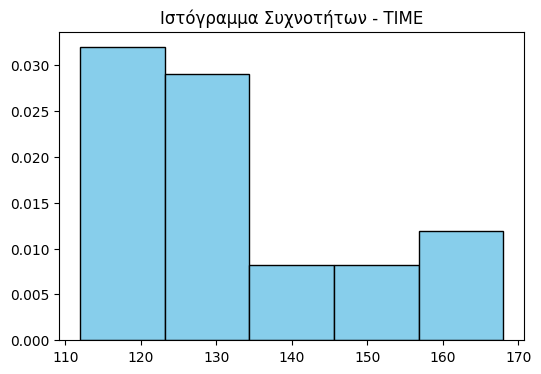

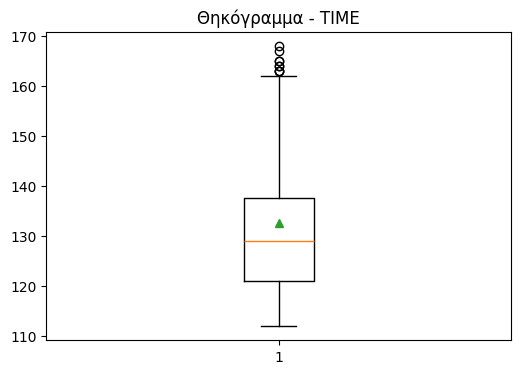

In [ ]:
# Β.1: Περιγραφικά μέτρα, Ιστόγραμμα και Θηκόγραμμα για το TIME
print("--- Β.1: Περιγραφικά Μέτρα για TIME ---")
print(TIME.describe())
print("Διασπορά (Variance):", TIME.var())
print("Εύρος (Range):", TIME.max() - TIME.min())
print("Ασυμμετρία (Skewness):", skew(TIME))
print("Κύρτωση (Kurtosis):", kurtosis(TIME))

# Ιστόγραμμα
plt.figure(figsize=(6,4))
plt.hist(TIME, bins=5, density=True, color='skyblue', edgecolor='black')
plt.title('Ιστόγραμμα Συχνοτήτων - TIME')
plt.show()

# Θηκόγραμμα
plt.figure(figsize=(6,4))
plt.boxplot(TIME, showmeans=True)
plt.title('Θηκόγραμμα - TIME')
plt.show()




**Β.1 — ΣΧΟΛΙΑΣΜΟΣ**

Η μεταβλητή TIME (μηνιαία λεπτά ομιλίας, n=120) έχει μέση τιμή 132.6 και διάμεσο 129.0. Η μέση τιμή είναι λίγο μεγαλύτερη από τη διάμεσο, πράγμα που δείχνει ότι η κατανομή γέρνει προς τα δεξιά (θετική ασυμμετρία) - το επιβεβαιώνει και ο συντελεστής ασυμμετρίας που είναι 0.90, δηλαδή θετικός.

Η τυπική απόκλιση είναι 15 λεπτά περίπου και το εύρος τιμών φτάνει τα 56 λεπτά (από 112 μέχρι 168), οπότε βλέπουμε αρκετή διασπορά γύρω από τον μέσο όρο.

Το ιστόγραμμα επιβεβαιώνει οπτικά τη δεξιά ασυμμετρία: οι περισσότερες παρατηρήσεις συγκεντρώνονται στις χαμηλότερες/μεσαίες τιμές, ενώ υπάρχουν λίγες αλλά αρκετά υψηλότερες τιμές που «τραβούν» την ουρά προς τα δεξιά. Το θηκόγραμμα δείχνει ότι η διάμεσος βρίσκεται πιο κοντά στο κάτω άκρο του κουτιού- πρώτο τεταρτημόριο(Q1) απ' ό,τι στο πάνω ακρο-τριτο τεταρτημόριο(Q3) — άλλη μια ένδειξη θετικής ασυμμετρίας — χωρίς εμφανείς ακραίες τιμές (outliers).


--- Β.2: Περιγραφικά Μέτρα TIME ανά Φύλο ---

Γυναίκες (MF=1):
count     66.000000
mean     133.727273
std       14.932201
min      112.000000
25%      122.250000
50%      129.500000
75%      145.000000
max      168.000000
Name: TIME, dtype: float64
Διασπορά: 222.97062937062938
Εύρος: 56
Ασυμμετρία: 0.8734137732603243

Άνδρες (MF=2):
count     54.000000
mean     131.277778
std       15.130148
min      113.000000
25%      120.000000
50%      127.000000
75%      134.750000
max      165.000000
Name: TIME, dtype: float64
Διασπορά: 228.9213836477988
Εύρος: 52
Ασυμμετρία: 0.9587123179726814


/tmp/ipykernel_384/3893723927.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([TIME1, TIME2], showmeans=True, labels=['Γυναίκες (MF=1)', 'Άνδρες (MF=2)'])


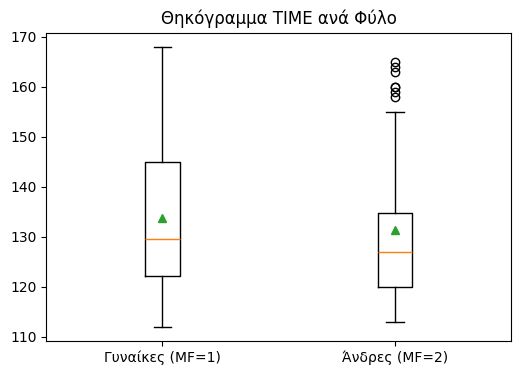

In [ ]:
# Β.2: Περιγραφικά μέτρα και Θηκογράμματα TIME ανά Φύλο (MF)
TIME1 = dfstat[dfstat['MF'] == 1]['TIME']
TIME2 = dfstat[dfstat['MF'] == 2]['TIME']

print("--- Β.2: Περιγραφικά Μέτρα TIME ανά Φύλο ---")
print("\nΓυναίκες (MF=1):")
print(TIME1.describe())
print("Διασπορά:", TIME1.var())
print("Εύρος:", TIME1.max() - TIME1.min())
print("Ασυμμετρία:", skew(TIME1))

print("\nΆνδρες (MF=2):")
print(TIME2.describe())
print("Διασπορά:", TIME2.var())
print("Εύρος:", TIME2.max() - TIME2.min())
print("Ασυμμετρία:", skew(TIME2))

# Θηκογράμματα
plt.figure(figsize=(6,4))
plt.boxplot([TIME1, TIME2], showmeans=True, labels=['Γυναίκες (MF=1)', 'Άνδρες (MF=2)'])
plt.title('Θηκόγραμμα TIME ανά Φύλο')
plt.show()



**Β.2 — ΣΧΟΛΙΑΣΜΟΣ**

Βλέποντας τα δύο φύλα ξεχωριστά, οι γυναίκες (n=66) έχουν λίγο μεγαλύτερο μέσο χρόνο ομιλίας (133.7 λεπτά) από τους άνδρες (n=54, 131.3 λεπτά). Η διαφορά είναι μικρή και μόνο κοιτώντας τα περιγραφικά μέτρα δεν μπορούμε να ξέρουμε αν είναι στατιστικά σημαντική - αυτό θα το δούμε στο Γ.2.

Και οι δύο υπο-ομάδες εμφανίζουν θετική ασυμμετρία (Skewness γυναικών = 0.87, Skewness ανδρών = 0.96), δηλαδή η μορφή της κατανομής διατηρείται παρόμοια και στα δύο φύλα. Όσον αφορά τα θηκογράμματα: οι γυναίκες έχουν μεγαλύτερο εύρος (22.75) στο τεταρτημόριά τους σε σχέση με τους άνδρες (14.75). Αυτό έχει ως αποτέλεσμα οι άνδρες να εμφανίζουν 7 ακραίες τιμές (outliers) στα δεξιά του θηκογράμματός τους (158-165 λεπτά), αφού το μικρότερο εύρος τους δημιουργεί στενότερα όρια γύρω από το κουτί. Οι γυναίκες αντίθετα δεν έχουν καμία ακραία τιμή, καθώς το μεγαλύτερο εύρος τους «χωράει» άνετα ακόμα και τη μέγιστη τιμή τους (168 λεπτά).


In [ ]:
# Γ.1: Έλεγχος μέσου χρόνου ομιλίας (ΤΙΜΕ) με τις 100 μονάδες

print("--- Γ.1: Έλεγχος Μέσης Τιμής (TIME vs 100) ---")
# H0: μ = 100 vs H1: μ != 100
t_stat1, p_val1 = stats.ttest_1samp(TIME, popmean=100)
print(f"T-statistic: {t_stat1:.4f}, P-value: {p_val1:.4e}")



--- Γ.1: Έλεγχος Μέσης Τιμής (TIME vs 100) ---
T-statistic: 23.8130, P-value: 4.3196e-47


**Γ.1 — ΣΧΟΛΙΑΣΜΟΣ**

**Υποθέσεις:**
- Η0: μ.ο = 100 (ο μέσος χρόνος ομιλίας ΤΙΜΕ στον πληθυσμό ισούται με 100 λεπτά)
- Η1: μ.ο ≠ 100 (διαφέρει από τα 100 λεπτά)

Εδώ κάνουμε δίπλευρο t-test για μία μέση τιμή δείγματος, αφού συγκρίνουμε τον μέσο όρο μας με μια σταθερή τιμή (100) και όχι με κάποια άλλη ομάδα.

Αν το p-value < α (=0.05) αυτό σημαίνει οτι απορρίπτουμε την Η0.

Το p-value που προέκυψε (4.3×10⁻⁴⁷) είναι πολύ μικρό, πολύ μικρότερο από το α=0.05, άρα απορρίπτουμε την Η0 και κρατάμε την Η1. Υπάρχουν πολύ ισχυρές στατιστικές ενδείξεις ότι ο πραγματικός (πληθυσμιακός) μέσος χρόνος ομιλίας διαφέρει στατιστικά σημαντικά από τις 100 μονάδες. Δεδομένου ότι η  μέση τιμή (132.6) του δείγματος είναι μεγαλύτερη από 100, συμπεραίνουμε ότι ο μέσος χρόνος ομιλίας στον πληθυσμό είναι στατιστικά σημαντικά υψηλότερος από τα 100 λεπτά.


In [ ]:
# Γ.2: Έλεγχος ισότητας μέσου χρόνου ομιλίας ανά φύλο

print("--- Γ.2: Έλεγχος ισότητας TIME ανά φύλο ---")
# H0: μ1 = μ2 vs H1: μ1 != μ2
# Ελέγχουμε πρώτα την ισότητα των διασπορών (Bartlett test)
b_stat, b_p = bartlett(TIME1, TIME2)
print(f"Bartlett test p-value: {b_p:.4f}")

# Διεξαγωγή T-test. Αν b_p > 0.05 θεωρούμε ίσες διασπορές.
t_stat2, p_val2 = stats.ttest_ind(TIME1, TIME2, equal_var=(b_p > 0.05))
print(f"T-statistic: {t_stat2:.4f}, P-value: {p_val2:.4f}")



--- Γ.2: Έλεγχος ισότητας TIME ανά φύλο ---
Bartlett test p-value: 0.2333
T-statistic: 0.8887, P-value: 0.3760


**Γ.2 — ΣΧΟΛΙΑΣΜΟΣ**

**Υποθέσεις (κύριος έλεγχος):**
- Η0: μ.ο_γυναικών = μ.ο_ανδρών (ο μέσος χρόνος ομιλίας είναι ίσος στα δύο φύλα)
- Η1: μ.ο_γυναικών ≠ μ.ο_ανδρών (διαφέρει)

Πρόκειται για έλεγχο ισότητας δύο ανεξάρτητων μέσων τιμών (independent samples t-test), αφού οι γυναίκες και οι άνδρες είναι δύο διαφορετικά και ανεξάρτητα υποσύνολα.

Η φόρμα υπολογισμού του τεστ (πώς υπολογίζεται το τυπικό σφάλμα) είναι διαφορετική στις δύο περιπτώσεις για αυτό πριν κάνουμε το t-test πρέπει πρώτα να μάθουμε αν οι διασπορές των δύο φύλων είναι ίσες ή όχι.
Γι' αυτό κάνουμε πρώτα το Bartlett test — είναι ένας ξεχωριστός, προκαταρκτικός έλεγχος που απαντάει ακριβώς σε αυτή την ερώτηση:
Οι υποθέσεις του Bartlett είναι:
- Η0_Bartlett: σ²_γυναικών = σ²_ανδρών
- Η1_Bartlett: σ²_γυναικών ≠ σ²_ανδρών

Αν το Bartlett test πει "οι διασπορές είναι ίσες" (δεν απορρίπτουμε Η0) → χρησιμοποιούμε Student's t-test (equal_var=True)
Αν το Bartlett test πει "οι διασπορές διαφέρουν" (απορρίπτουμε Η0) οποτε χρησιμοποιούμε Welch's t-test (equal_var=False)

Στην περίπτωσή μας, το Bartlett έβγαλε p=0.2333 (πολύ μεγάλο), άρα οι διασπορές είναι-θεωρούνται στατιστικά ίσες, και γι' αυτό χρησιμοποιήσαμε το κανονικό (Student's) t-test.

**Κύριο συμπέρασμα:** το p-value του t-test είναι 0.376, πολύ μεγαλύτερο από α=0.05. Άρα ΔΕΝ απορρίπτουμε την Η0 δηλαδη δεν υπάρχουν στατιστικά σημαντικές ενδείξεις ότι ο μέσος χρόνος ομιλίας διαφέρει ανάμεσα στα δύο φύλα στον πληθυσμό — η μικρή διαφορά που παρατηρήσαμε περιγραφικά (133.7 έναντι 131.3) οφείλεται πιθανότατα στην τυχαία δειγματοληψία.


In [ ]:
# Γ.3: Έλεγχος μηνιαίου ποσοστού χρήσης WhatsApp ανά φύλο

print("--- Γ.3: Έλεγχος χρήσης WhatsApp ανά φύλο ---")
W1 = dfstat[dfstat['MF'] == 1]['WhatsApp']
W2 = dfstat[dfstat['MF'] == 2]['WhatsApp']

# H0: p1 = p2 vs H1: p1 != p2
t_stat3, p_val3 = stats.ttest_ind(W1, W2)
print(f"T-statistic: {t_stat3:.4f}, P-value: {p_val3:.4f}")



--- Γ.3: Έλεγχος χρήσης WhatsApp ανά φύλο ---
T-statistic: -0.8947, P-value: 0.3727


**Γ.3 — ΣΧΟΛΙΑΣΜΟΣ**

Η μεταβλητή WhatsApp είναι δίτιμη (0 = δεν χρησιμοποιεί, 1 = χρησιμοποιεί), οπότε ο μέσος όρος της ισοδυναμεί ακριβώς με το ποσοστό (αναλογία) χρηστών που τη χρησιμοποιούν. Θέλουμε να συγκρίνουμε αυτό το ποσοστό ανάμεσα στα δύο φύλα.

**Υποθέσεις:**
- Η0: p_γυναικών = p_ανδρών (το ποσοστό χρήσης WhatsApp είναι ίδιο στα δύο φύλα)
- Η1: p_γυναικών ≠ p_ανδρών (τα ποσοστά διαφέρουν)

Χρησιμοποιούμε t-test ανεξάρτητων δειγμάτων πάνω στη δίτιμη μεταβλητή, το οποίο λειτουργεί εδώ ως προσέγγιση ελέγχου ισότητας δύο ποσοστών καθώς η σύγκριση των μέσων όρων μιας μεταβλητής 0 ή 1 ισοδυναμεί με σύγκριση ποσοστών. Ουσιαστικά η βασική ιδέα ειναι οτι όταν μια μεταβλητή παίρνει μόνο τιμές 0 και 1 (όπως το WhatsApp: 0=δεν χρησιμοποιεί, 1=χρησιμοποιεί), τότε ο μέσος όρος αυτής της μεταβλητής είναι αυτόματα ίσος με το ποσοστό των ατόμων που έχουν την τιμή 1

Στο δείγμα, το ποσοστό χρήσης είναι 45.5% στις γυναίκες και 53.7% στους άνδρες. Το p-value που προέκυψε είναι 0.373, μεγαλύτερο από α=0.05, άρα ΔΕΝ απορρίπτουμε την Η0. Δεν υπάρχουν επαρκείς στατιστικές ενδείξεις ότι το ποσοστό χρήσης WhatsApp για τηλεφωνική επικοινωνία διαφέρει ανάμεσα στα δύο φύλα στον πληθυσμό.


In [ ]:
# Γ.4: Έλεγχος αποτελεσματικότητας διαφημιστικής εκστρατείας

print("--- Γ.4: Ζευγαρωτός έλεγχος (Μείωση χρόνου λόγω διαφήμισης) ---")
# Η διαφημιστική εκστρατεία μείωσε το χρόνο;
# H0: TIME <= TIME_AFTER vs H1: TIME > TIME_AFTER
t_stat4, p_val4 = stats.ttest_rel(TIME, TIME_AFTER, alternative='greater')
print(f"T-statistic: {t_stat4:.4f}, P-value: {p_val4:.4e}")



--- Γ.4: Ζευγαρωτός έλεγχος (Μείωση χρόνου λόγω διαφήμισης) ---
T-statistic: 5.2464, P-value: 3.4218e-07


**Γ.4 — ΣΧΟΛΙΑΣΜΟΣ**

Εδώ παρατηρούμε οτι έχουμε δύο μετρήσεις πάνω στα ίδια άτομα (πριν και μετά τη διαφημιστική εκστρατεία), άρα πρόκειται για εξαρτημένες παρατηρήσεις και χρησιμοποιούμε paired t-test (όχι independent t-test).

Θέλουμε να ελέγξουμε συγκεκριμένα αν η εκστρατεία μείωσε τον χρόνο ομιλίας, δηλαδή αν μ.ο_TIME > μ.ο_TIME_AFTER:

**Υποθέσεις:**
- Η0: μ.ο_TIME ≤ μ.ο_TIME_AFTER (η εκστρατεία δεν μείωσε τον χρόνο ομιλίας)
- Η1: μ.ο_TIME > μ.ο_TIME_AFTER (η εκστρατεία μείωσε τον χρόνο ομιλίας)

Επειδή μας ενδιαφέρει συγκεκριμένη κατεύθυνση (μείωση, όχι απλά "διαφορά"), πρόκειται για μονόπλευρο (one-sided) έλεγχο, γι' αυτό χρησιμοποιείται alternative='greater.

Ο μέσος χρόνος πριν την εκστρατεία ήταν 132.6 λεπτά, ενώ μετά έπεσε στα 130.9 λεπτά. Το p-value που προέκυψε (3.42×10⁻⁷) είναι πολύ μικρότερο από α=0.05, άρα απορρίπτουμε την Η0. Υπάρχουν ισχυρές στατιστικές ενδείξεις ότι η διαφημιστική εκστρατεία μείωσε στατιστικά σημαντικά τον μέσο χρόνο ομιλίας — αποτέλεσμα συμβατό με τον στόχο της εκστρατείας (μετατόπιση από κλήσεις προς SMS).


In [ ]:
# Γ.5: Έλεγχος ANOVA - TIME ανά εταιρεία (TELECOM)

print("--- Γ.5: Έλεγχος ANOVA - TIME ανά TELECOM ---")
T1 = dfstat[dfstat['TELECOM'] == 1]['TIME']
T2 = dfstat[dfstat['TELECOM'] == 2]['TIME']
T3 = dfstat[dfstat['TELECOM'] == 3]['TIME']

# Έλεγχος ομοιογένειας διασπορών πριν την ANOVA
bart_stat, bart_p = stats.bartlett(T1, T2, T3)
print(f"Bartlett statistic: {bart_stat:.4f}, P-value: {bart_p:.4f}")

# H0: μ1 = μ2 = μ3 vs H1: Τουλάχιστον ένα ζεύγος διαφέρει
f_stat, p_val5 = f_oneway(T1, T2, T3)
print(f"F-statistic: {f_stat:.4f}, P-value: {p_val5:.5f}")



--- Γ.5: Έλεγχος ANOVA - TIME ανά TELECOM ---
Bartlett statistic: 1.7780, P-value: 0.4111
F-statistic: 3.0635, P-value: 0.05049


**Γ.5 — ΣΧΟΛΙΑΣΜΟΣ**

Θέλουμε να δούμε αν ο μέσος χρόνος ομιλίας διαφέρει ανάμεσα στις τρεις εταιρείες τηλεπικοινωνίας (TELECOM=1,2,3). Επειδή συγκρίνουμε περισσότερες από δύο μέσες τιμές ταυτόχρονα, χρησιμοποιούμε One-Way ANOVA (και όχι πολλαπλά t-tests γιατί θα αύξαναν το σφάλμα τύπου Ι).

**Υποθέσεις:**
- Η0: μ1 = μ2 = μ3 (ο μέσος χρόνος ομιλίας είναι ίδιος και στις τρεις εταιρείες)
- Η1: τουλάχιστον μία εταιρεία έχει διαφορετικό μέσο χρόνο ομιλίας από τις άλλες

Η ANOVA προϋποθέτει την ομοιογένεια διασπορών ανάμεσα στις ομάδες· ελέγχοντάς το ξεχωριστά με Bartlett test (p=0.4111 > 0.05)και αφού η προϋπόθεση αυτή ικανοποιείται η εφαρμογή της ANOVA είναι έγκυρη.


Το p-value που προέκυψε από την ANOVA είναι 0.05049, οριακά πάνω από το επίπεδο σημαντικότητας α=0.05. Επειδή τυπικά 0.05049 > 0.05, ΔΕΝ απορρίπτουμε την Η0 στο α=5%. Συμπεραίνουμε ότι δεν υπάρχει επαρκής στατιστική ένδειξη πως ο μέσος χρόνος ομιλίας διαφέρει ανάμεσα στις τρεις εταιρείες, αν και το αποτέλεσμα είναι **πολύ οριακό** (marginally non-significant) επίσης απο αυτό βλεπουμε οτι μια ελαφρώς διαφορετική τιμή δείγματος θα μπορούσε εύκολα να οδηγήσει στο αντίθετο συμπέρασμα.

Σημείωση: επειδή η Η0 δεν απορρίφθηκε, δεν χρειάζεται  έλεγχος για τον εντοπισμό συγκεκριμένων ζευγών εταιρειών που διαφέρουν, αφού η ANOVA δεν εντόπισε συνολικά στατιστικά σημαντική διαφορά.


In [ ]:
# Δ.1, Δ.2, Δ.3: Πίνακες Συνάφειας MF και WhatsApp

print("--- Δ.1: Πίνακας Διπλής Εισόδου ---")
CT_W = pd.crosstab(index=MF, columns=WhatsApp)
display(CT_W)

print("\n--- Δ.2: Περιθώριες Σχετικές Συχνότητες ---")
display(pd.crosstab(index=MF, columns=WhatsApp, margins=True, normalize=True))


print("\n--- Δ.3: Δεσμευμένες Σχετικές Συχνότητες ως προς Φύλο ---")
display(pd.crosstab(index=MF, columns=WhatsApp, normalize='index'))


--- Δ.1: Πίνακας Διπλής Εισόδου ---


WhatsApp,0,1
MF,,
1,36,30
2,25,29



--- Δ.2: Περιθώριες Σχετικές Συχνότητες ---


WhatsApp,0,1,All
MF,,,
1,0.300000,0.250000,0.55
2,0.208333,0.241667,0.45
All,0.508333,0.491667,1.00



--- Δ.3: Δεσμευμένες Σχετικές Συχνότητες ως προς Φύλο ---


WhatsApp,0,1
MF,,
1,0.545455,0.454545
2,0.462963,0.537037


**Δ.1** — ** Πλήθος ατόμων**

Οι γυναίκες ειναι ΜF=1 και MF= είναι οι άντρες.
ο και 1 στο whatsapp ειναι αν το χρησιμουποιούν ή οχι.
Το σύνολο ειναι 120 διότι 36+30+25+29=120

**Δ.2 — ΕΡΜΗΝΕΙΑ (Περιθώριες σχετικές συχνότητες)**

Οι περιθώριες σχετικές συχνότητες προκύπτουν αθροίζοντας κατά γραμμή ή στήλη, και δείχνουν την κατανομή κάθε μεταβλητής μόνη της, χωρίς να κοιτάμε την άλλη.


Γυναίκες σύνολο = 36+30 = 66 άτομα αρα 66/120 = 55%

Άνδρες σύνολο = 25+29 = 54 άτομα αρα 54/120 = 45%

Το "55%" και το "45%" που βλέπουμε στη γραμμή "All" (στήλη) — δείχνει την κατανομή του φύλου μόνο και αγνοούσαμε τελείως το WhatsApp.
Στη συνέχεια έχουμε την ερώτηση τι ποσοστό όλων δεν χρησιμοποιεί WhatsApp;

Σύνολο χωρίς WhatsApp = 36+25 = 61 αρα 61/120 = 50.8%
Σύνολο με WhatsApp = 30+29 = 59 αρα 59/120 = 49.2%


**Δ.3 — ΕΡΜΗΝΕΙΑ (Δεσμευμένες σχετικές συχνότητες)**

Εδώ υπολογίζουμε ξεχωριστά μέσα σε κάθε γραμμή (κάθε φύλο), ώστε να αθροίζει 100%. Δείχνουν το ποσοστό χρήσης WhatsApp δεδομένου του φύλου - δηλαδή, μέσα σε κάθε φύλο ξεχωριστά, τι ποσοστό χρησιμοποιεί WhatsApp.

Γυναίκες χωρίς WhatsApp:
36 από τις 66 γυναίκες → 36/66 = 54.5%
Γυναίκες με WhatsApp:
30 από τις 66 γυναίκες → 30/66 = 45.5%
(54.5% + 45.5% = 100% — όλες οι γυναίκες μαζί)



Άνδρες χωρίς WhatsApp:
25 από τους 54 άνδρες αρα 25/54 = 46.3%
Άνδρες με WhatsApp:
29 από τους 54 άνδρες αρα 29/54 = 53.7%
(46.3% + 53.7% = 100% — όλοι οι άνδρες μαζί)

Λέγονται "δεσμευμένες ως προς το φύλο" γιατί η ερώτηση είναι: δεδομένου ότι κάποιος είναι γυναίκα, ποια είναι η πιθανότητα να χρησιμοποιεί WhatsApp; Κοιτάμε μέσα στην ομάδα, όχι στο σύνολο.





In [ ]:
# Δ.4: Έλεγχος Ανεξαρτησίας χ² για MF και WhatsApp

print("--- Δ.4: Έλεγχος Ανεξαρτησίας χ² ---")
# H0: MF και WhatsApp είναι ανεξάρτητα
chi2_w, p_chi_w, dof_w, exp_w = chi2_contingency(CT_W)
print(f"Chi-square: {chi2_w:.4f}, P-value: {p_chi_w:.4f}")



--- Δ.4: Έλεγχος Ανεξαρτησίας χ² ---
Chi-square: 0.5123, P-value: 0.4742


**Δ.4 — ΣΧΟΛΙΑΣΜΟΣ**

Θέλουμε να δούμε αν η χρήση WhatsApp εξαρτάται από το φύλο.

**Υποθέσεις:**
- Η0: οι μεταβλητές MF και WhatsApp είναι **ανεξάρτητες** (η χρήση WhatsApp δεν εξαρτάται από το φύλο)
- Η1: οι μεταβλητές MF και WhatsApp είναι **εξαρτημένες** (η χρήση WhatsApp σχετίζεται με το φύλο)

Χρησιμοποιούμε τον έλεγχο χ² ανεξαρτησίας ο οποίος συγκρίνει τις παρατηρούμενες συχνότητες του πίνακα συνάφειας με τις αναμενόμενες συχνότητες που θα περιμέναμε αν οι δύο μεταβλητές ήταν πράγματι ανεξάρτητες. Όσο μεγαλύτερη είναι η απόκλιση παρατηρούμενων-αναμενόμενων, τόσο μεγαλύτερη η στατιστική χ² και τόσο μικρότερο το p-value.

Το p-value που προέκυψε (0.474) είναι πολύ μεγαλύτερο από α=0.05, άρα ΔΕΝ απορρίπτουμε την Η0. Συμπεραίνουμε ότι δεν υπάρχει στατιστικά σημαντική εξάρτηση ανάμεσα στο φύλο και τη χρήση WhatsApp — η μικρή διαφορά ποσοστών που παρατηρήσαμε στο Δ.3 (45.5% έναντι 53.7%) οφείλεται πιθανότατα στην τυχαία δειγματοληψία και όχι σε πραγματική σχέση των δύο μεταβλητών στον πληθυσμό.


In [ ]:
# Δ.5: Μετασχηματισμός TIME σε ιεραρχική (TIMECATEGORICAL) & Έλεγχος χ²

print("--- Δ.5: Μετασχηματισμός TIME και Έλεγχος χ² ---")

# Δημιουργία 5 ισοπληθών κατηγοριών χρησιμοποιώντας την qcut (πεντημόρια)
TIMECAT = pd.qcut(TIME, q=5, labels=['1','2','3','4','5'])

CT_CAT = pd.crosstab(index=MF, columns=TIMECAT)
print("\nΠίνακας Διπλής Εισόδου MF & TIMECATEGORICAL:")
display(CT_CAT)

# H0: MF και TIMECATEGORICAL είναι ανεξάρτητα
chi2_cat, p_chi_cat, dof_cat, exp_cat = chi2_contingency(CT_CAT)
print(f"\nChi-square: {chi2_cat:.4f}, P-value: {p_chi_cat:.4f}")



--- Δ.5: Μετασχηματισμός TIME και Έλεγχος χ² ---

Πίνακας Διπλής Εισόδου MF & TIMECATEGORICAL:


TIME,1,2,3,4,5
MF,,,,,
1,11,13,14,15,13
2,15,11,10,8,10



Chi-square: 2.7984, P-value: 0.5921


**Δ.5 — ΣΧΟΛΙΑΣΜΟΣ**
Πρώτα μετατρέπουμε το TIME σε πεντάτιμη κατηγορική μεταβλητή, χωρίζοντας τις τιμές σε 5 ισοπληθή κομμάτια (πεντημόρια) με τη qcut - η κατηγορία '1' αντιστοιχεί στις χαμηλότερες τιμές και η '5' στις υψηλότερες.
Μετά ελέγχουμε αν αυτή η νέα μεταβλητή σχετίζεται με το φύλο:
Υποθέσεις:

Η0: οι μεταβλητές MF και TIMECATEGORICAL είναι ανεξάρτητες
Η1: είναι εξαρτημένες

Κάνουμε ξανά χ² έλεγχο ανεξαρτησίας. Το p-value βγήκε 0.592, πολύ πάνω από το 0.05, άρα δεν απορρίπτουμε την Η0. Η κατανομή του χρόνου ομιλίας φαίνεται ανεξάρτητη από το φύλο - συνεπές, άλλωστε, με το συμπέρασμα του Γ.2, όπου είχαμε δει ότι ο μέσος χρόνος δεν διαφέρει σημαντικά ανάμεσα στα φύλα.


Τέλος δεν έβαλα ελέγχους κανονικότητας (Shapiro-Wilk) γιατί δεν ζητούνται και έπίσης έχουμε αρκετά μεγάλο δείγμα (n=120 με πολλές υποομάδες (φύλου και εταιρειών), οπότε τα t-tests και η ANOVA δουλεύουν αξιόπιστα ακόμα κι αν τα δεδομένα δεν είναι απόλυτα κανονικά.